In [3]:
# Block 1: Load and inspect the semi-synthetic LAOS observations

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


DATA_DIR = Path(".")

METADATA_PATH = DATA_DIR / "metadata.json"

if not METADATA_PATH.is_file():
    METADATA_PATH = DATA_DIR / "metadata.json"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Benchmark metadata not found in: {DATA_DIR.resolve()}"
    )

with METADATA_PATH.open("r", encoding="utf-8") as file:
    benchmark_metadata = json.load(file)

expected_name = "APR18-based semi-synthetic LAOS change benchmark v2"

if benchmark_metadata.get("name") != expected_name:
    raise ValueError("The metadata does not identify the expected benchmark.")

OBSERVED_DIR = DATA_DIR / "observable"

if not OBSERVED_DIR.is_dir():
    OBSERVED_DIR = DATA_DIR

case_files = {
    "control": "control.csv",
    "change_10pct": "change_10pct.csv",
    "change_20pct": "change_20pct.csv",
    "change_30pct": "change_30pct.csv",
}

# Support the renamed control attachment.
if not (OBSERVED_DIR / "control.csv").is_file():
    case_files["control"] = "control(2).csv"

required_columns = [
    "time_s",
    "strain",
    "shear_rate_1_s",
    "stress_Pa",
]

OMEGA_RAD_S = 1.0
FUNDAMENTAL_HZ = OMEGA_RAD_S / (2.0 * np.pi)
PERIOD_S = 1.0 / FUNDAMENTAL_HZ

expected_rows = int(benchmark_metadata["sampling"]["rows"])
expected_start_s = float(benchmark_metadata["sampling"]["start_s"])
expected_end_s = float(benchmark_metadata["sampling"]["end_s"])

laos_records = {}
inspection_rows = []

for case_name, filename in case_files.items():
    file_path = OBSERVED_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(f"Observation file not found: {file_path}")

    data = pd.read_csv(file_path)

    if not set(required_columns).issubset(data.columns):
        raise ValueError(f"Unexpected columns in {filename}")

    data = data[required_columns].apply(
        pd.to_numeric,
        errors="raise",
    )

    if not np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError(f"Missing or nonfinite values in {filename}")

    times_s = data["time_s"].to_numpy()
    intervals_s = np.diff(times_s)

    if len(data) != expected_rows or np.any(intervals_s <= 0):
        raise ValueError(f"Unexpected row count or timestamps in {filename}")

    if not np.allclose(
        times_s[[0, -1]],
        [expected_start_s, expected_end_s],
        rtol=0.0,
        atol=1e-8,
    ):
        raise ValueError(f"Unexpected time range in {filename}")

    median_dt_s = float(np.median(intervals_s))
    sampling_hz = 1.0 / median_dt_s

    laos_records[case_name] = {
        "data": data.reset_index(drop=True),
        "omega_rad_s": OMEGA_RAD_S,
        "fundamental_hz": FUNDAMENTAL_HZ,
        "period_s": PERIOD_S,
        "median_sampling_hz": sampling_hz,
    }

    inspection_rows.append({
        "case": case_name,
        "n_samples": len(data),
        "first_time_s": times_s[0],
        "last_time_s": times_s[-1],
        "median_sampling_hz": sampling_hz,
        "max_dt_deviation_percent": (
            100.0
            * np.max(np.abs(intervals_s - median_dt_s))
            / median_dt_s
        ),
        "fundamental_hz": FUNDAMENTAL_HZ,
        "period_s": PERIOD_S,
        "stress_min_Pa": data["stress_Pa"].min(),
        "stress_max_Pa": data["stress_Pa"].max(),
    })

control_inputs = laos_records["control"]["data"][
    ["time_s", "strain", "shear_rate_1_s"]
].to_numpy()

for case_name, record in laos_records.items():
    case_inputs = record["data"][
        ["time_s", "strain", "shear_rate_1_s"]
    ].to_numpy()

    if not np.array_equal(case_inputs, control_inputs):
        raise ValueError(f"Input mismatch between control and {case_name}")

laos_data_summary = pd.DataFrame(inspection_rows)

print("Benchmark:", benchmark_metadata["name"])
print("Observation directory:", OBSERVED_DIR.resolve())

display(laos_data_summary.round(5))

print("\nFirst rows of the control observations:")
display(laos_records["control"]["data"].head())

print("\nAll four cases have identical time, strain, and shear-rate inputs.")
print("Original timestamps are retained. No resampling has been applied.")
print("Truth files have not been loaded.")

Benchmark: APR18-based semi-synthetic LAOS change benchmark v2
Observation directory: /Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/observable


,case,n_samples,first_time_s,last_time_s,median_sampling_hz,max_dt_deviation_percent,fundamental_hz,period_s,stress_min_Pa,stress_max_Pa
0,control,1995,0.04027,39.9953,50.0,1.5,0.15915,6.28319,-0.18310,0.17974
1,change_10pct,1995,0.04027,39.9953,50.0,1.5,0.15915,6.28319,-0.19593,0.19359
2,change_20pct,1995,0.04027,39.9953,50.0,1.5,0.15915,6.28319,-0.21372,0.21119
3,change_30pct,1995,0.04027,39.9953,50.0,1.5,0.15915,6.28319,-0.23152,0.22879



First rows of the control observations:


,time_s,strain,shear_rate_1_s,stress_Pa
0,0.040270,0.275039,10.429139,0.051781
1,0.060290,0.490818,10.277151,0.128133
2,0.080309,0.690293,10.147457,0.134659
3,0.100329,0.890095,10.040057,0.127726
4,0.120592,1.089520,9.954951,0.142433



All four cases have identical time, strain, and shear-rate inputs.
Original timestamps are retained. No resampling has been applied.
Truth files have not been loaded.


In [4]:
# Block 2: Resample all observations onto a common uniform time grid

SAMPLING_HZ = 50.0
DT_S = 1.0 / SAMPLING_HZ

control_data = laos_records["control"]["data"]
original_times_s = control_data["time_s"].to_numpy()

# Keep the grid within the measured time range.
first_grid_index = int(np.ceil(original_times_s[0] * SAMPLING_HZ))
last_grid_index = int(np.floor(original_times_s[-1] * SAMPLING_HZ))

uniform_times_s = (
    np.arange(first_grid_index, last_grid_index + 1)
    / SAMPLING_HZ
)

if len(uniform_times_s) < 2:
    raise ValueError("The uniform time grid is too short.")

if (
    uniform_times_s[0] < original_times_s[0]
    or uniform_times_s[-1] > original_times_s[-1]
):
    raise ValueError("The uniform grid extends beyond the measured data.")

laos_prepared_records = {}
resampling_rows = []

signal_columns = [
    "strain",
    "shear_rate_1_s",
    "stress_Pa",
]

for case_name, record in laos_records.items():
    original_data = record["data"]
    times_s = original_data["time_s"].to_numpy()

    prepared_data = pd.DataFrame({
        "time_s": uniform_times_s,
    })

    for column in signal_columns:
        prepared_data[column] = np.interp(
            uniform_times_s,
            times_s,
            original_data[column].to_numpy(),
        )

    if not np.isfinite(prepared_data.to_numpy()).all():
        raise ValueError(f"Invalid resampled values in {case_name}")

    prepared_record = record.copy()
    prepared_record["data"] = prepared_data
    prepared_record["sampling_hz"] = SAMPLING_HZ

    laos_prepared_records[case_name] = prepared_record

    resampling_rows.append({
        "case": case_name,
        "original_n_samples": len(original_data),
        "uniform_n_samples": len(prepared_data),
        "first_time_s": uniform_times_s[0],
        "last_time_s": uniform_times_s[-1],
        "sampling_hz": SAMPLING_HZ,
        "uniform_dt_s": DT_S,
        "interpolation": "linear",
    })

resampling_summary = pd.DataFrame(resampling_rows)

display(resampling_summary.round(5))

print("\nFirst rows of the uniformly sampled control:")
display(laos_prepared_records["control"]["data"].head())

print("\nOriginal observations remain in laos_records.")
print("Uniformly sampled observations are stored in laos_prepared_records.")
print("All cases use the same time grid.")
print("No extrapolation, filtering, or amplitude normalization was applied.")

,case,original_n_samples,uniform_n_samples,first_time_s,last_time_s,sampling_hz,uniform_dt_s,interpolation
0,control,1995,1997,0.06,39.98,50.0,0.02,linear
1,change_10pct,1995,1997,0.06,39.98,50.0,0.02,linear
2,change_20pct,1995,1997,0.06,39.98,50.0,0.02,linear
3,change_30pct,1995,1997,0.06,39.98,50.0,0.02,linear



First rows of the uniformly sampled control:


,time_s,strain,shear_rate_1_s,stress_Pa
0,0.06,0.487695,10.279350,0.127028
1,0.08,0.687212,10.149460,0.134558
2,0.10,0.886812,10.041822,0.127840
3,0.12,1.083694,9.957437,0.142003
4,0.14,1.282456,9.894060,0.145563



Original observations remain in laos_records.
Uniformly sampled observations are stored in laos_prepared_records.
All cases use the same time grid.
No extrapolation, filtering, or amplitude normalization was applied.


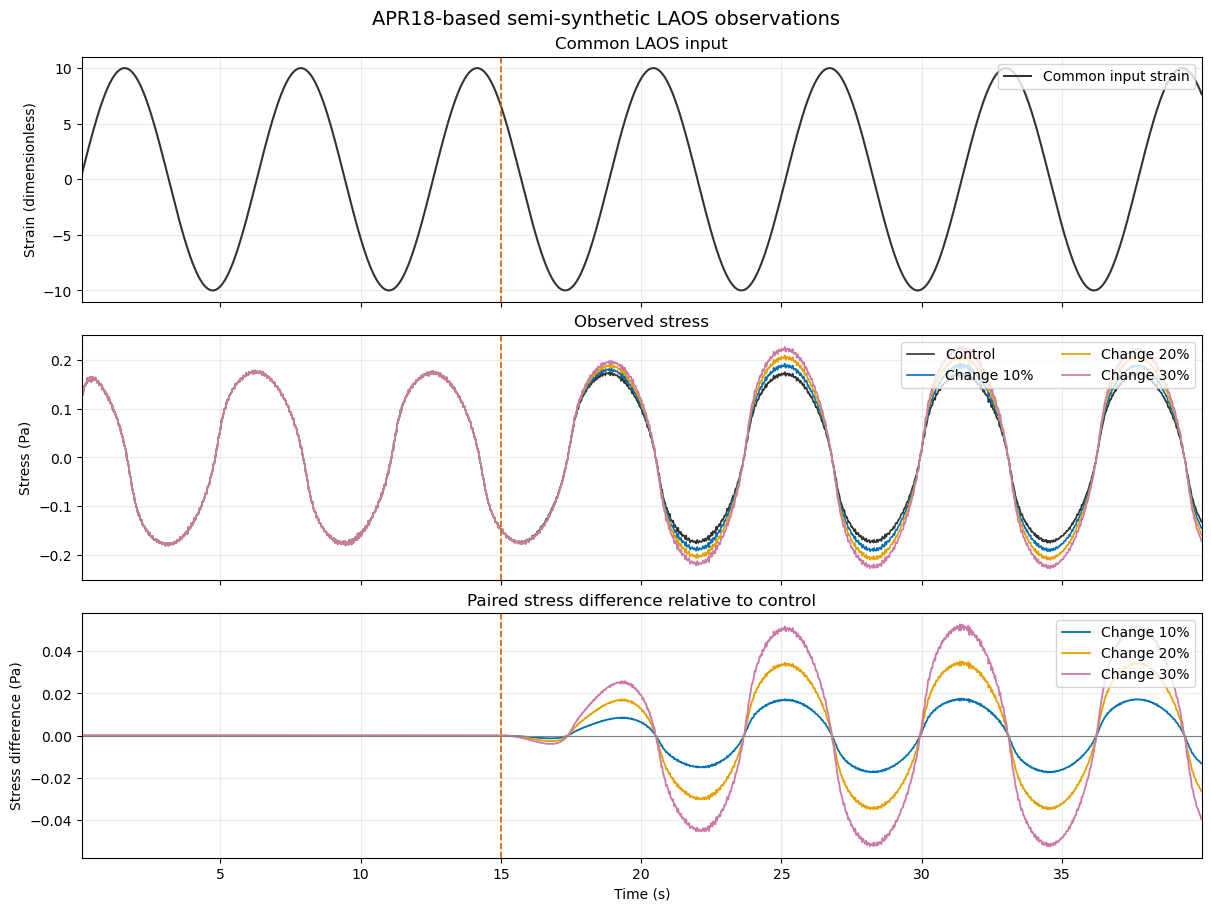

The dashed line marks the specified injection onset.
Paired stress differences are used for benchmark inspection only.
No change detector has been applied.


In [5]:
# Block 3: Inspect the input strain and stress differences

CASE_LABELS = {
    "control": "Control",
    "change_10pct": "Change 10%",
    "change_20pct": "Change 20%",
    "change_30pct": "Change 30%",
}

CASE_COLORS = {
    "control": "#333333",
    "change_10pct": "#0072B2",
    "change_20pct": "#E69F00",
    "change_30pct": "#CC79A7",
}

# This marker describes the benchmark design.
# It is not a detected change time.
DESIGN_ONSET_S = float(
    benchmark_metadata["construction"]["onset_s"]
)

control_prepared = laos_prepared_records["control"]["data"]
times_s = control_prepared["time_s"].to_numpy()
control_stress_Pa = control_prepared["stress_Pa"].to_numpy()

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 9),
    sharex=True,
    constrained_layout=True,
)

# The input strain is identical across all four cases.
axes[0].plot(
    times_s,
    control_prepared["strain"],
    color=CASE_COLORS["control"],
    linewidth=1.5,
    label="Common input strain",
)

axes[0].set_title("Common LAOS input")
axes[0].set_ylabel("Strain (dimensionless)")
axes[0].legend(loc="upper right")

stress_difference_tables = {}

for case_name, record in laos_prepared_records.items():
    data = record["data"]
    stress_Pa = data["stress_Pa"].to_numpy()

    axes[1].plot(
        times_s,
        stress_Pa,
        color=CASE_COLORS[case_name],
        linewidth=1.2,
        label=CASE_LABELS[case_name],
    )

    if case_name == "control":
        continue

    difference_Pa = stress_Pa - control_stress_Pa

    stress_difference_tables[case_name] = pd.DataFrame({
        "time_s": times_s,
        "stress_difference_Pa": difference_Pa,
    })

    axes[2].plot(
        times_s,
        difference_Pa,
        color=CASE_COLORS[case_name],
        linewidth=1.3,
        label=CASE_LABELS[case_name],
    )

axes[1].set_title("Observed stress")
axes[1].set_ylabel("Stress (Pa)")
axes[1].legend(loc="upper right", ncol=2)

axes[2].set_title("Paired stress difference relative to control")
axes[2].set_ylabel("Stress difference (Pa)")
axes[2].set_xlabel("Time (s)")
axes[2].axhline(0.0, color="gray", linewidth=0.8)
axes[2].legend(loc="upper right")

for ax in axes:
    ax.axvline(
        DESIGN_ONSET_S,
        color="#D55E00",
        linestyle="--",
        linewidth=1.2,
    )
    ax.grid(alpha=0.25)
    ax.set_xlim(times_s[0], times_s[-1])

fig.suptitle(
    "APR18-based semi-synthetic LAOS observations",
    fontsize=14,
)

time_domain_figure = fig
plt.show()

print("The dashed line marks the specified injection onset.")
print("Paired stress differences are used for benchmark inspection only.")
print("No change detector has been applied.")

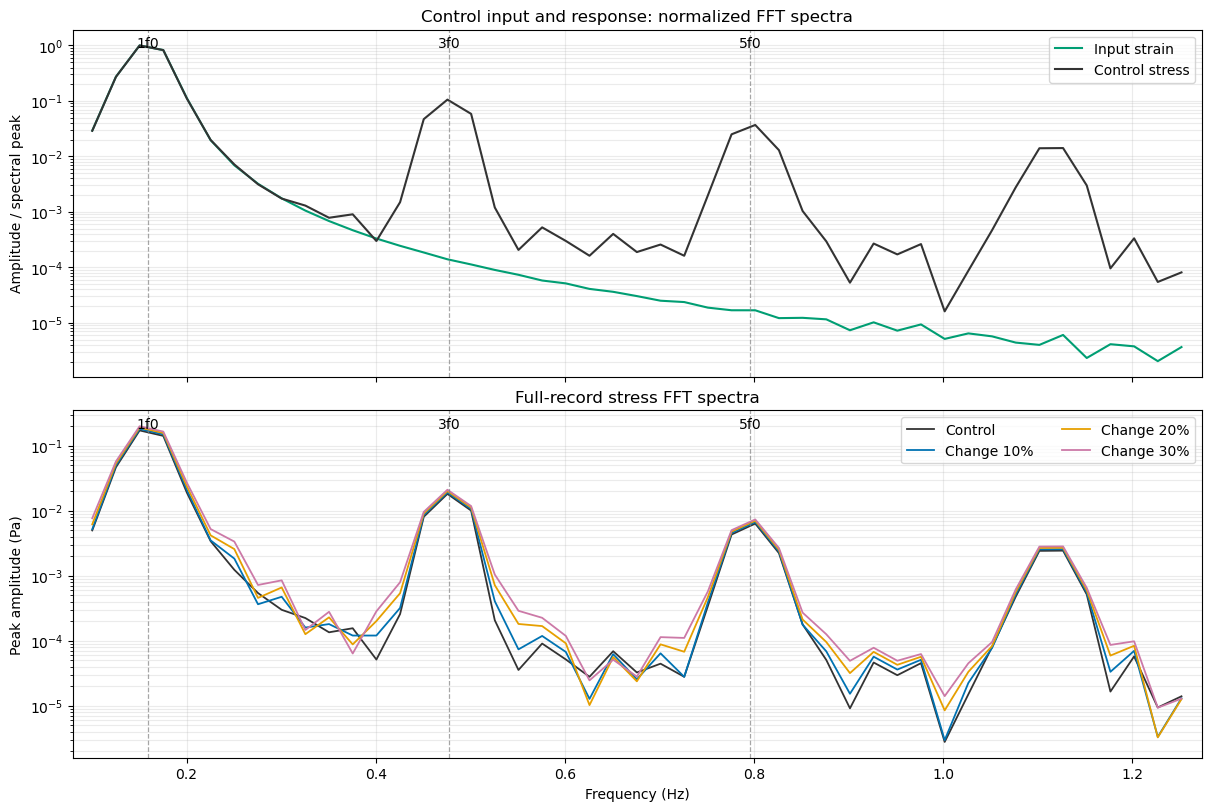

Fundamental frequency: 0.159155 Hz
Third harmonic frequency: 0.477465 Hz
Fifth harmonic frequency: 0.795775 Hz
FFT frequency-bin spacing: 0.025038 Hz

Full-record spectra summarize the complete observation period.
Harmonic amplitudes will be estimated separately at target frequencies.
No candidate change time is calculated in this block.


In [6]:
# Block 4: Compute and inspect the full-record FFT spectra

def compute_laos_fft(signal_values, sampling_hz):
    values = np.asarray(signal_values, dtype=float)

    if values.ndim != 1 or len(values) < 4:
        raise ValueError("The signal must be a one-dimensional array.")

    if not np.isfinite(values).all() or sampling_hz <= 0:
        raise ValueError("Invalid signal values or sampling rate.")

    n_samples = len(values)
    sample_indices = np.arange(n_samples)

    # Remove the mean and apply a periodic Hann window.
    centered_values = values - np.mean(values)
    window = (
        0.5
        - 0.5 * np.cos(2.0 * np.pi * sample_indices / n_samples)
    )

    fft_values = np.fft.rfft(centered_values * window)
    frequencies_hz = np.fft.rfftfreq(
        n_samples,
        d=1.0 / sampling_hz,
    )

    # Correct for the window coherent gain.
    amplitudes = np.abs(fft_values) / np.sum(window)

    # Convert to a one-sided peak-amplitude spectrum.
    if n_samples % 2 == 0:
        amplitudes[1:-1] *= 2.0
    else:
        amplitudes[1:] *= 2.0

    return {
        "frequency_hz": frequencies_hz,
        "amplitude": amplitudes,
        "n_samples": n_samples,
        "frequency_bin_spacing_hz": sampling_hz / n_samples,
        "window_duration_s": n_samples / sampling_hz,
    }


full_record_stress_spectra = {}

for case_name, record in laos_prepared_records.items():
    full_record_stress_spectra[case_name] = compute_laos_fft(
        record["data"]["stress_Pa"].to_numpy(),
        record["sampling_hz"],
    )

control_strain_spectrum = compute_laos_fft(
    laos_prepared_records["control"]["data"]["strain"].to_numpy(),
    SAMPLING_HZ,
)

control_stress_spectrum = full_record_stress_spectra["control"]

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True,
)

frequency_limits_hz = (
    0.5 * FUNDAMENTAL_HZ,
    8.0 * FUNDAMENTAL_HZ,
)

# Normalize each control spectrum separately to compare spectral shape.
for spectrum, label, color in [
    (control_strain_spectrum, "Input strain", "#009E73"),
    (control_stress_spectrum, "Control stress", "#333333"),
]:
    frequencies_hz = spectrum["frequency_hz"]
    amplitudes = spectrum["amplitude"]

    band_mask = (
        (frequencies_hz >= frequency_limits_hz[0])
        & (frequencies_hz <= frequency_limits_hz[1])
    )

    peak_amplitude = np.max(amplitudes[band_mask])

    if peak_amplitude <= 0:
        raise ValueError("Cannot normalize a zero-amplitude spectrum.")

    axes[0].semilogy(
        frequencies_hz[band_mask],
        np.maximum(amplitudes[band_mask] / peak_amplitude, 1e-8),
        color=color,
        linewidth=1.5,
        label=label,
    )

axes[0].set_title("Control input and response: normalized FFT spectra")
axes[0].set_ylabel("Amplitude / spectral peak")
axes[0].legend()

# Retain physical amplitude units for the four stress spectra.
for case_name, spectrum in full_record_stress_spectra.items():
    frequencies_hz = spectrum["frequency_hz"]
    band_mask = (
        (frequencies_hz >= frequency_limits_hz[0])
        & (frequencies_hz <= frequency_limits_hz[1])
    )

    axes[1].semilogy(
        frequencies_hz[band_mask],
        np.maximum(spectrum["amplitude"][band_mask], 1e-12),
        color=CASE_COLORS[case_name],
        linewidth=1.3,
        label=CASE_LABELS[case_name],
    )

axes[1].set_title("Full-record stress FFT spectra")
axes[1].set_ylabel("Peak amplitude (Pa)")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].legend(ncol=2)

for ax in axes:
    for harmonic in [1, 3, 5]:
        target_hz = harmonic * FUNDAMENTAL_HZ

        ax.axvline(
            target_hz,
            color="gray",
            linestyle="--",
            linewidth=0.9,
            alpha=0.7,
        )

        ax.text(
            target_hz,
            0.98,
            f"{harmonic}f0",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=10,
        )

    ax.set_xlim(*frequency_limits_hz)
    ax.grid(alpha=0.25, which="both")

full_record_fft_figure = fig
plt.show()

print(f"Fundamental frequency: {FUNDAMENTAL_HZ:.6f} Hz")
print(f"Third harmonic frequency: {3 * FUNDAMENTAL_HZ:.6f} Hz")
print(f"Fifth harmonic frequency: {5 * FUNDAMENTAL_HZ:.6f} Hz")
print(
    "FFT frequency-bin spacing: "
    f"{control_stress_spectrum['frequency_bin_spacing_hz']:.6f} Hz"
)
print("\nFull-record spectra summarize the complete observation period.")
print("Harmonic amplitudes will be estimated separately at target frequencies.")
print("No candidate change time is calculated in this block.")

In [7]:
# Block 5: Estimate harmonic amplitudes in early and late segments

HARMONIC_ORDERS = [1, 3, 5]
SEGMENT_CYCLES = 2.0

N_SEGMENT = int(
    round(SEGMENT_CYCLES * PERIOD_S * SAMPLING_HZ)
)

SEGMENT_STARTS_S = {
    "early": 2.0,
    "late": 26.0,
}

HARMONIC_FEATURES = [
    "I1_Pa",
    "I3_Pa",
    "I5_Pa",
    "I3_I1",
    "I5_I1",
]


def estimate_target_harmonics(
    signal_values,
    sampling_hz,
    fundamental_hz,
):
    values = np.asarray(signal_values, dtype=float)

    if values.ndim != 1 or len(values) < 4:
        raise ValueError("Invalid signal shape or length.")

    if not np.isfinite(values).all():
        raise ValueError("The signal contains nonfinite values.")

    if (
        sampling_hz <= 0
        or fundamental_hz <= 0
        or 5 * fundamental_hz >= sampling_hz / 2
    ):
        raise ValueError("Invalid sampling or harmonic frequencies.")

    n_samples = len(values)
    sample_indices = np.arange(n_samples)
    relative_times_s = sample_indices / sampling_hz

    window = (
        0.5
        - 0.5 * np.cos(2.0 * np.pi * sample_indices / n_samples)
    )

    centered_values = values - np.mean(values)

    amplitudes = []

    for harmonic in HARMONIC_ORDERS:
        target_hz = harmonic * fundamental_hz

        complex_coefficient = np.sum(
            window
            * centered_values
            * np.exp(-2j * np.pi * target_hz * relative_times_s)
        )

        amplitude = (
            2.0 * np.abs(complex_coefficient) / np.sum(window)
        )

        amplitudes.append(float(amplitude))

    return np.asarray(amplitudes)


segment_records = {}
segment_rows = []
stress_rows = []
strain_rows = []

for segment_name, requested_start_s in SEGMENT_STARTS_S.items():
    start_index = int(
        np.searchsorted(uniform_times_s, requested_start_s)
    )
    stop_index = start_index + N_SEGMENT

    if stop_index > len(uniform_times_s):
        raise ValueError(f"Insufficient data for the {segment_name} segment.")

    actual_start_s = float(uniform_times_s[start_index])
    exclusive_end_s = actual_start_s + N_SEGMENT / SAMPLING_HZ

    if segment_name == "early" and exclusive_end_s > DESIGN_ONSET_S:
        raise ValueError("The early segment overlaps the injected change.")

    segment_rows.append({
        "segment": segment_name,
        "start_s": actual_start_s,
        "end_exclusive_s": exclusive_end_s,
        "n_samples": N_SEGMENT,
        "duration_s": N_SEGMENT / SAMPLING_HZ,
        "cycles": N_SEGMENT / SAMPLING_HZ / PERIOD_S,
    })

    for case_name, record in laos_prepared_records.items():
        segment_data = (
            record["data"]
            .iloc[start_index:stop_index]
            .reset_index(drop=True)
        )

        segment_records[(case_name, segment_name)] = segment_data

        I1, I3, I5 = estimate_target_harmonics(
            segment_data["stress_Pa"].to_numpy(),
            SAMPLING_HZ,
            FUNDAMENTAL_HZ,
        )

        if I1 <= np.finfo(float).eps:
            raise ValueError(f"Invalid fundamental amplitude in {case_name}")

        stress_rows.append({
            "case": case_name,
            "segment": segment_name,
            "I1_Pa": I1,
            "I3_Pa": I3,
            "I5_Pa": I5,
            "I3_I1": I3 / I1,
            "I5_I1": I5 / I1,
        })

        if case_name == "control":
            strain_I1, strain_I3, strain_I5 = estimate_target_harmonics(
                segment_data["strain"].to_numpy(),
                SAMPLING_HZ,
                FUNDAMENTAL_HZ,
            )

            if strain_I1 <= np.finfo(float).eps:
                raise ValueError("Invalid input fundamental amplitude.")

            strain_rows.append({
                "segment": segment_name,
                "strain_I1": strain_I1,
                "strain_I3_I1": strain_I3 / strain_I1,
                "strain_I5_I1": strain_I5 / strain_I1,
            })

fft_segment_summary = pd.DataFrame(segment_rows)
fft_harmonic_summary = pd.DataFrame(stress_rows)
fft_input_harmonic_summary = pd.DataFrame(strain_rows)

control_features = (
    fft_harmonic_summary
    .loc[fft_harmonic_summary["case"] == "control"]
    .set_index("segment")
)

paired_rows = []

for row in stress_rows:
    if row["case"] == "control":
        continue

    paired_row = {
        "case": row["case"],
        "segment": row["segment"],
    }

    for feature in HARMONIC_FEATURES:
        reference_value = float(
            control_features.loc[row["segment"], feature]
        )

        paired_row[f"{feature}_difference_percent"] = (
            100.0 * (row[feature] - reference_value) / reference_value
            if abs(reference_value) > np.finfo(float).eps
            else np.nan
        )

    paired_rows.append(paired_row)

fft_paired_harmonic_comparison = pd.DataFrame(paired_rows)

print("Analysis segments:")
display(fft_segment_summary.round(5))

print("\nInput strain harmonic estimates:")
display(fft_input_harmonic_summary.round(7))

print("\nStress harmonic estimates:")
display(fft_harmonic_summary.round(7))

print("\nFeature differences relative to control in the same segment (%):")
display(fft_paired_harmonic_comparison.round(4))

print("\nI1, I3, and I5 represent estimated peak amplitudes, not powers.")
print("Segment comparisons support interpretation, not change-time detection.")

Analysis segments:


,segment,start_s,end_exclusive_s,n_samples,duration_s,cycles
0,early,2.0,14.56,628,12.56,1.99899
1,late,26.0,38.56,628,12.56,1.99899



Input strain harmonic estimates:


,segment,strain_I1,strain_I3_I1,strain_I5_I1
0,early,10.001965,0.000037,0.000011
1,late,10.001813,0.000037,0.000010



Stress harmonic estimates:


,case,segment,I1_Pa,I3_Pa,I5_Pa,I3_I1,I5_I1
0,control,early,0.189661,0.018935,0.006744,0.099838,0.035561
1,change_10pct,early,0.189661,0.018935,0.006744,0.099838,0.035561
2,change_20pct,early,0.189661,0.018935,0.006744,0.099838,0.035561
3,change_30pct,early,0.189661,0.018935,0.006744,0.099838,0.035561
4,control,late,0.185177,0.017837,0.006444,0.096321,0.034801
5,change_10pct,late,0.203692,0.019620,0.007089,0.096321,0.034801
6,change_20pct,late,0.222207,0.021403,0.007733,0.096322,0.034801
7,change_30pct,late,0.240723,0.023187,0.008377,0.096322,0.034801



Feature differences relative to control in the same segment (%):


,case,segment,I1_Pa_difference_percent,I3_Pa_difference_percent,I5_Pa_difference_percent,I3_I1_difference_percent,I5_I1_difference_percent
0,change_10pct,early,0.0000,0.0000,0.0000,0.0000,0.0000
1,change_20pct,early,0.0000,0.0000,0.0000,0.0000,0.0000
2,change_30pct,early,0.0000,0.0000,0.0000,0.0000,0.0000
3,change_10pct,late,9.9987,9.9988,9.9982,0.0001,-0.0005
4,change_20pct,late,19.9974,19.9977,19.9964,0.0002,-0.0008
5,change_30pct,late,29.9961,29.9965,29.9946,0.0003,-0.0012



I1, I3, and I5 represent estimated peak amplitudes, not powers.
Segment comparisons support interpretation, not change-time detection.


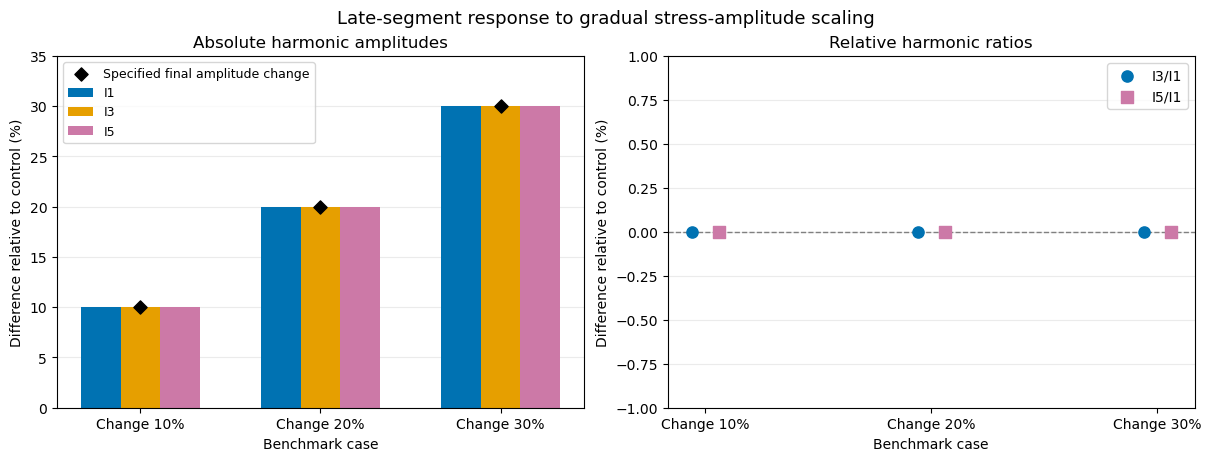

Amplitude changes approximately match the specified final changes.
Relative harmonic ratios remain approximately unchanged.
The ratio panel uses a fixed scale from -1% to +1%.
These paired comparisons do not provide a detected onset time.


In [8]:
# Block 6: Visualize late-segment feature changes relative to control

change_cases = [
    "change_10pct",
    "change_20pct",
    "change_30pct",
]

late_comparison = (
    fft_paired_harmonic_comparison
    .loc[fft_paired_harmonic_comparison["segment"] == "late"]
    .set_index("case")
    .loc[change_cases]
)

expected_changes_percent = np.array([
    100.0
    * benchmark_metadata["construction"]["alpha_by_case"][case]
    for case in change_cases
])

x_positions = np.arange(len(change_cases))
bar_width = 0.22

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    constrained_layout=True,
)

amplitude_specs = [
    ("I1_Pa", "I1", "#0072B2"),
    ("I3_Pa", "I3", "#E69F00"),
    ("I5_Pa", "I5", "#CC79A7"),
]

for index, (feature, label, color) in enumerate(amplitude_specs):
    values = late_comparison[
        f"{feature}_difference_percent"
    ].to_numpy()

    axes[0].bar(
        x_positions + (index - 1) * bar_width,
        values,
        width=bar_width,
        color=color,
        label=label,
    )

axes[0].scatter(
    x_positions,
    expected_changes_percent,
    color="black",
    marker="D",
    s=45,
    zorder=5,
    label="Specified final amplitude change",
)

axes[0].set_title("Absolute harmonic amplitudes")
axes[0].set_ylabel("Difference relative to control (%)")
axes[0].set_ylim(0, 35)
axes[0].legend(fontsize=9)

ratio_specs = [
    ("I3_I1", "I3/I1", "#0072B2", "o"),
    ("I5_I1", "I5/I1", "#CC79A7", "s"),
]

for index, (feature, label, color, marker) in enumerate(ratio_specs):
    values = late_comparison[
        f"{feature}_difference_percent"
    ].to_numpy()

    axes[1].scatter(
        x_positions + (index - 0.5) * 0.12,
        values,
        color=color,
        marker=marker,
        s=65,
        label=label,
        zorder=3,
    )

axes[1].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
)

axes[1].set_title("Relative harmonic ratios")
axes[1].set_ylabel("Difference relative to control (%)")
axes[1].set_ylim(-1, 1)
axes[1].legend()

for ax in axes:
    ax.set_xticks(
        x_positions,
        [CASE_LABELS[case] for case in change_cases],
    )
    ax.set_xlabel("Benchmark case")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Late-segment response to gradual stress-amplitude scaling",
    fontsize=13,
)

harmonic_comparison_figure = fig
plt.show()

print("Amplitude changes approximately match the specified final changes.")
print("Relative harmonic ratios remain approximately unchanged.")
print("The ratio panel uses a fixed scale from -1% to +1%.")
print("These paired comparisons do not provide a detected onset time.")

In [9]:
# Block 7: Export FFT results, figures, and analysis settings

from datetime import datetime
import hashlib

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

fft_output_dir = (
    DATA_DIR / "results" / f"FFT_semisynthetic_{timestamp}"
)
fft_output_dir.mkdir(parents=True, exist_ok=False)

tables_to_export = {
    "data_inspection.csv": laos_data_summary,
    "resampling_summary.csv": resampling_summary,
    "analysis_segments.csv": fft_segment_summary,
    "input_harmonics.csv": fft_input_harmonic_summary,
    "stress_harmonics.csv": fft_harmonic_summary,
    "paired_harmonic_comparison.csv": fft_paired_harmonic_comparison,
}

for filename, table in tables_to_export.items():
    table.to_csv(
        fft_output_dir / filename,
        index=False,
        float_format="%.12g",
    )

stress_spectrum_rows = []

for case_name, spectrum in full_record_stress_spectra.items():
    stress_spectrum_rows.append(pd.DataFrame({
        "case": case_name,
        "frequency_hz": spectrum["frequency_hz"],
        "peak_amplitude_Pa": spectrum["amplitude"],
    }))

pd.concat(
    stress_spectrum_rows,
    ignore_index=True,
).to_csv(
    fft_output_dir / "full_record_stress_spectra.csv",
    index=False,
    float_format="%.12g",
)

pd.DataFrame({
    "frequency_hz": control_strain_spectrum["frequency_hz"],
    "peak_amplitude_dimensionless": control_strain_spectrum["amplitude"],
}).to_csv(
    fft_output_dir / "full_record_input_spectrum.csv",
    index=False,
    float_format="%.12g",
)

figures_to_export = {
    "time_domain": time_domain_figure,
    "full_record_fft": full_record_fft_figure,
    "late_harmonic_comparison": harmonic_comparison_figure,
}

for name, figure in figures_to_export.items():
    figure.savefig(
        fft_output_dir / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    figure.savefig(
        fft_output_dir / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )

source_file_hashes = {}

for case_name, filename in case_files.items():
    file_path = OBSERVED_DIR / filename

    source_file_hashes[case_name] = {
        "filename": filename,
        "sha256": hashlib.sha256(file_path.read_bytes()).hexdigest(),
    }

fft_analysis_config = {
    "benchmark_name": benchmark_metadata["name"],
    "sampling_hz": SAMPLING_HZ,
    "fundamental_hz": FUNDAMENTAL_HZ,
    "period_s": PERIOD_S,
    "interpolation": "linear",
    "extrapolation": False,
    "additional_startup_removal": False,
    "mean_removal": True,
    "window": "periodic Hann",
    "amplitude_definition": "one-sided peak amplitude",
    "harmonic_estimator": "windowed Fourier projection at nominal frequencies",
    "harmonic_orders": HARMONIC_ORDERS,
    "segment_samples": N_SEGMENT,
    "segments": fft_segment_summary.to_dict(orient="records"),
    "full_record_frequency_bin_spacing_hz": (
        control_stress_spectrum["frequency_bin_spacing_hz"]
    ),
    "design_onset_s": DESIGN_ONSET_S,
    "truth_files_loaded": False,
    "change_detector_applied": False,
    "source_observation_files": source_file_hashes,
}

with (fft_output_dir / "analysis_config.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        fft_analysis_config,
        file,
        indent=2,
        allow_nan=False,
    )

analysis_notes = """
FFT analysis of the APR18-based semi-synthetic LAOS benchmark

Purpose
Inspect the input and stress spectra and interpret the injected amplitude changes.

Findings
The input strain is approximately sinusoidal.
The measured control stress contains appreciable third and fifth harmonics.
This supports a nonlinear stress response under the imposed LAOS input.
Early-segment harmonic features are identical across the four cases.
Late-segment absolute harmonic amplitudes increase by approximately 10%, 20%,
and 30% relative to the control in the same segment.
Late-segment relative harmonic ratios remain approximately unchanged.

Interpretation
The benchmark introduces gradual overall stress-amplitude scaling.
It does not specifically introduce stronger relative harmonic distortion.
The control already exhibits nonlinear response before any injected change.

Limitations
Full-record FFT combines observations before and after the injected change.
Target-frequency projections remain finite-window amplitude estimates.
Paired control comparisons are benchmark diagnostics.
No candidate change time or detection delay has been estimated here.
These results do not establish clinical clotting time or general performance
across donors.

Next step
Extract time-resolved STFT features and evaluate a frozen alarm rule.
""".strip()

(fft_output_dir / "analysis_notes.txt").write_text(
    analysis_notes + "\n",
    encoding="utf-8",
)

print("FFT results saved to:")
print(fft_output_dir.resolve())

print("\nExported files:")
for file_path in sorted(fft_output_dir.iterdir()):
    print(file_path.name)

FFT results saved to:
/Users/g.y/Desktop/Project team 35/code/apr18_semisynthetic_laos_v2/results/FFT_semisynthetic_20261010_234517_183367

Exported files:
analysis_config.json
analysis_notes.txt
analysis_segments.csv
data_inspection.csv
full_record_fft.pdf
full_record_fft.png
full_record_input_spectrum.csv
full_record_stress_spectra.csv
input_harmonics.csv
late_harmonic_comparison.pdf
late_harmonic_comparison.png
paired_harmonic_comparison.csv
resampling_summary.csv
stress_harmonics.csv
time_domain.pdf
time_domain.png
